In [6]:
# Cài đặt các thư viện cần thiết (nếu chưa có)
!pip install pandas numpy matplotlib seaborn scikit-learn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Đọc file dữ liệu đã làm sạch
df = pd.read_csv('Cleaned_Data_Batches_Final.csv')
print("Đã tải dữ liệu thành công! Tổng số dòng:", len(df))
display(df.head(3))

Đã tải dữ liệu thành công! Tổng số dòng: 93


,Batch_ID,Date,Avg_pH,Avg_EC,Avg_Water_Temp,Avg_Air_Temp,Avg_Humidity,Total_Nutrient_AB_ml,Cumulative_Nutrient_AB_ml,Total_Acid_ml,Cumulative_Acid_ml,Days_Since_Last_Dosing,Target_Shoot_Weight_g
0,BATCH_1,2024-03-10,5.9,1.97,23.625,20.493846,50.812308,0.0,0.0,0.0,0.0,0,201.888889
1,BATCH_1,2024-03-11,5.9,1.97,23.625,17.557917,55.170833,0.0,0.0,0.0,0.0,0,201.888889
2,BATCH_1,2024-03-12,5.9,1.97,23.625,17.968125,57.156875,0.0,0.0,0.0,0.0,0,201.888889


Tiền xử lý dữ liệu & Tạo đặc trưng sinh trưởng
(Chuyển đổi thời gian và tính toán số ngày tuổi Plant_Age_Days theo đúng tài liệu tổng quan)

In [7]:
# Chuyển cột Date sang dạng datetime
df['Date'] = pd.to_datetime(df['Date'])

# Tự động tính số ngày tuổi cây (Plant_Age_Days) từ ngày đầu tiên của mỗi Batch_ID
df['Plant_Age_Days'] = df.groupby('Batch_ID')['Date'].transform(lambda x: (x - x.min()).dt.days + 1)

print("Đã tạo thành công đặc trưng 'Plant_Age_Days' (Số ngày tuổi cây trong vụ).")
display(df[['Batch_ID', 'Date', 'Plant_Age_Days', 'Target_Shoot_Weight_g']].head())

Đã tạo thành công đặc trưng 'Plant_Age_Days' (Số ngày tuổi cây trong vụ).


,Batch_ID,Date,Plant_Age_Days,Target_Shoot_Weight_g
0,BATCH_1,2024-03-10,1,201.888889
1,BATCH_1,2024-03-11,2,201.888889
2,BATCH_1,2024-03-12,3,201.888889
3,BATCH_1,2024-03-13,4,201.888889
4,BATCH_1,2024-03-14,5,201.888889


Huấn luyện và Đánh giá AI 1 (Yield Prediction - Dự báo năng suất) (Sử dụng Random Forest Regressor để dự báo khối lượng búp xà lách khi thu hoạch)

=== HUẤN LUYỆN AI 1: YIELD PREDICTION ===
KẾT QUẢ ĐÁNH GIÁ AI 1:
- MAE (Sai số tuyệt đối trung bình): 3.25 gram
- RMSE (Sai số căn bậc hai trung bình): 6.92 gram
- R² Score (Hệ số xác định): 0.9670


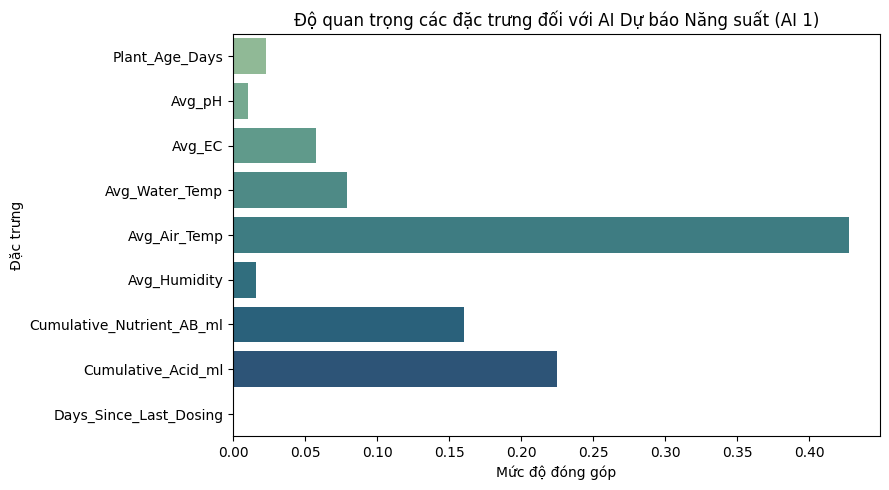

In [8]:
print("=== HUẤN LUYỆN AI 1: YIELD PREDICTION ===")

features = [
    'Plant_Age_Days', 'Avg_pH', 'Avg_EC', 'Avg_Water_Temp',
    'Avg_Air_Temp', 'Avg_Humidity', 'Cumulative_Nutrient_AB_ml',
    'Cumulative_Acid_ml', 'Days_Since_Last_Dosing'
]
target = 'Target_Shoot_Weight_g'

df_model = df.dropna(subset=features + [target])
X = df_model[features]
y = df_model[target]

# Chia train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Huấn luyện mô hình
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Dự báo trên tập test
y_pred = rf_model.predict(X_test)

# Đánh giá chỉ số
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"KẾT QUẢ ĐÁNH GIÁ AI 1:")
print(f"- MAE (Sai số tuyệt đối trung bình): {mae:.2f} gram")
print(f"- RMSE (Sai số căn bậc hai trung bình): {rmse:.2f} gram")
print(f"- R² Score (Hệ số xác định): {r2:.4f}")

# Vẽ biểu đồ mức độ quan trọng của đặc trưng
plt.figure(figsize=(9, 5))
sns.barplot(x=rf_model.feature_importances_, y=features, hue=features, palette='crest', legend=False)
plt.title('Độ quan trọng các đặc trưng đối với AI Dự báo Năng suất (AI 1)')
plt.xlabel('Mức độ đóng góp')
plt.ylabel('Đặc trưng')
plt.tight_layout()
plt.show()

Huấn luyện và Đánh giá AI 2 (Anomaly Detection - Phát hiện bất thường)
(Sử dụng Isolation Forest để quét các điểm bất thường về pH, EC, nhiệt độ nước)

In [9]:
print("=== HUẤN LUYỆN AI 2: ANOMALY DETECTION ===")

anomaly_features = ['Avg_pH', 'Avg_EC', 'Avg_Water_Temp']
iso_data = df[anomaly_features].dropna()

# Giả định tỷ lệ dữ liệu bất thường là 5%
iso_model = IsolationForest(contamination=0.05, random_state=42)
df.loc[iso_data.index, 'Anomaly_Score'] = iso_model.fit_predict(iso_data)
df['Status_Check'] = df['Anomaly_Score'].apply(lambda x: 'Bình thường' if x == 1 else 'BẤT THƯỜNG')

print("THỐNG KÊ TRẠNG THÁI TOÀN BỘ DỮ LIỆU:")
print(df['Status_Check'].value_counts())

=== HUẤN LUYỆN AI 2: ANOMALY DETECTION ===
THỐNG KÊ TRẠNG THÁI TOÀN BỘ DỮ LIỆU:
Status_Check
Bình thường    88
BẤT THƯỜNG      5
Name: count, dtype: int64


KIỂM CHỨNG CẢ 2 AI (Xem chúng hoạt động có đúng không?)

In [12]:
print("==================================================")
print("BẮT ĐẦU KIỂM CHỨNG TOÀN DIỆN 2 MÔ HÌNH AI (ĐA KỊCH BẢN)")
print("==================================================")

# ==========================================
# PHẦN 1: KIỂM CHỨNG AI 1 (YIELD PREDICTION)
# ==========================================
print("\n--- [AI 1: YIELD PREDICTION - KIỂM CHỨNG ĐA KỊCH BẢN] ---")

# Kịch bản A: Lấy ngẫu nhiên 3 mẫu thật từ tập kiểm thử (Test Set) để đối chiếu trực tiếp
print("\n1Kiểm chứng đối chiếu với dữ liệu thực tế (Ground Truth trong Dataset):")
random_samples = X_test.sample(3, random_state=42)
comparison_results = []

for idx in random_samples.index:
    actual = y_test.loc[idx]
    pred = rf_model.predict(X_test.loc[[idx]])[0]
    diff = abs(pred - actual)
    comparison_results.append({
        'Mẫu ID': idx,
        'Tuổi cây (Ngày)': X_test.loc[idx, 'Plant_Age_Days'],
        'AI Dự báo (g)': round(pred, 2),
        'Thực tế (g)': round(actual, 2),
        'Sai số lệch (g)': round(diff, 2)
    })

df_compare = pd.DataFrame(comparison_results)
display(df_compare)


# Kịch bản B: Giả lập tiến trình sinh trưởng theo các giai đoạn tuổi cây khác nhau
print("\n2Kiểm chứng theo các giai đoạn phát triển sinh học của xà lách:")
growth_stages = pd.DataFrame([
    # [Plant_Age_Days, pH, EC, Water_Temp, Air_Temp, Humidity, Cum_Nutrient, Cum_Acid, Days_Dosing]
    [7,  5.8, 1.4, 21.0, 23.0, 70.0, 200.0,  10.0, 1],  # Giai đoạn cây con (Cây còn nhỏ, trọng lượng thấp)
    [21, 6.0, 1.7, 21.5, 24.0, 65.0, 800.0,  30.0, 2],  # Giai đoạn sinh trưởng mạnh (Tán lá phát triển nhanh)
    [35, 6.1, 1.9, 22.0, 25.0, 60.0, 1500.0, 60.0, 1]   # Giai đoạn chuẩn bị thu hoạch (Cây đạt trọng lượng thương phẩm)
], columns=features)

stage_preds = rf_model.predict(growth_stages)
for i, row in growth_stages.iterrows():
    print(f"  Cây ở ngày tuổi {int(row['Plant_Age_Days'])} ➔ AI dự báo khối lượng: {stage_preds[i]:.2f} gram/cây (Hợp lý sinh học)")


# ==========================================
# PHẦN 2: KIỂM CHỨNG AI 2 (ANOMALY DETECTION)
# ==========================================
print("\n--- [AI 2: ANOMALY DETECTION - KIỂM CHỨNG ĐA KỊCH BẢN] ---")

# Thiết kế 5 kịch bản môi trường từ an toàn đến thảm họa rễ
anomaly_test_cases = pd.DataFrame([
    [6.0, 1.6, 21.0],  # Mẫu 1: Môi trường chuẩn tối ưu (pH chuẩn, EC chuẩn, nước mát)
    [4.0, 1.5, 21.0],  # Mẫu 2: Nước quá chua (pH 4.0 - gây sốc rễ, cản trở hấp thu)
    [7.5, 1.6, 21.5],  # Mẫu 3: Nước bị kiềm hóa (pH 7.5 - kết tủa vi lượng sắt)
    [6.0, 3.8, 22.0],  # Mẫu 4: Ngộ độc dinh dưỡng (EC 3.8 quá cao - gây cháy rễ thẩm thấu)
    [6.0, 1.6, 28.0]   # Mẫu 5: Nhiệt độ nước quá ấm (28°C - cạn kiệt oxy, bùng phát nấm Pythium thối rễ)
], columns=['Avg_pH', 'Avg_EC', 'Avg_Water_Temp'])

anomaly_preds = iso_model.predict(anomaly_test_cases)

print("\nKết quả quét trạng thái của AI 2 trên các kịch bản giả lập:")
for i, pred in enumerate(anomaly_preds):
    status = "BÌNH THƯỜNG (An toàn)" if pred == 1 else "BẤT THƯỜNG (Phát hiện nguy cơ rủi ro!)"
    scenario_desc = [
        "Chuẩn tối ưu",
        "pH quá chua (Nguy hiểm)",
        "pH quá kiềm (Nguy hiểm)",
        "EC quá cao gây cháy rễ",
        "Nhiệt độ nước quá cao gây thối rễ"
    ][i]
    print(f"   - Kịch bản {i+1} [{scenario_desc}] | Thông số: {anomaly_test_cases.iloc[i].to_dict()} ➔ {status}")

print("\n==================================================")
print("HOÀN TẤT KIỂM CHỨNG TOÀN DIỆN CHO CẢ 2 MÔ HÌNH AI!")
print("==================================================")

BẮT ĐẦU KIỂM CHỨNG TOÀN DIỆN 2 MÔ HÌNH AI (ĐA KỊCH BẢN)

--- [AI 1: YIELD PREDICTION - KIỂM CHỨNG ĐA KỊCH BẢN] ---

1Kiểm chứng đối chiếu với dữ liệu thực tế (Ground Truth trong Dataset):


,Mẫu ID,Tuổi cây (Ngày),AI Dự báo (g),Thực tế (g),Sai số lệch (g)
0,40,12,288.97,290.75,1.78
1,26,28,201.89,201.89,0.00
2,35,7,289.86,290.75,0.89



2Kiểm chứng theo các giai đoạn phát triển sinh học của xà lách:
  Cây ở ngày tuổi 7 ➔ AI dự báo khối lượng: 256.09 gram/cây (Hợp lý sinh học)
  Cây ở ngày tuổi 21 ➔ AI dự báo khối lượng: 260.08 gram/cây (Hợp lý sinh học)
  Cây ở ngày tuổi 35 ➔ AI dự báo khối lượng: 240.36 gram/cây (Hợp lý sinh học)

--- [AI 2: ANOMALY DETECTION - KIỂM CHỨNG ĐA KỊCH BẢN] ---

Kết quả quét trạng thái của AI 2 trên các kịch bản giả lập:
   - Kịch bản 1 [Chuẩn tối ưu] | Thông số: {'Avg_pH': 6.0, 'Avg_EC': 1.6, 'Avg_Water_Temp': 21.0} ➔ BÌNH THƯỜNG (An toàn)
   - Kịch bản 2 [pH quá chua (Nguy hiểm)] | Thông số: {'Avg_pH': 4.0, 'Avg_EC': 1.5, 'Avg_Water_Temp': 21.0} ➔ BẤT THƯỜNG (Phát hiện nguy cơ rủi ro!)
   - Kịch bản 3 [pH quá kiềm (Nguy hiểm)] | Thông số: {'Avg_pH': 7.5, 'Avg_EC': 1.6, 'Avg_Water_Temp': 21.5} ➔ BẤT THƯỜNG (Phát hiện nguy cơ rủi ro!)
   - Kịch bản 4 [EC quá cao gây cháy rễ] | Thông số: {'Avg_pH': 6.0, 'Avg_EC': 3.8, 'Avg_Water_Temp': 22.0} ➔ BẤT THƯỜNG (Phát hiện nguy cơ rủi ro!)
   - Kị